In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from lightgbm import LGBMRegressor
from prophet import Prophet

from sklearn.model_selection import TimeSeriesSplit

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

file_path = (
    "C:/Users/RSCH/Desktop/DWD/Final project/"
    "Retail-Intelligence-Platform/datasets/"
    "amez_dataset_feature_engineered.xlsx"
)

data = pd.read_excel(
    file_path,
    sheet_name="Feature_Data"
)

data["InvoiceDate"] = pd.to_datetime(
    data["InvoiceDate"]
)

print("Dataset loaded successfully")
print("Dataset shape:", data.shape)
print(data.head())
print(data.columns.tolist())


Dataset loaded successfully
Dataset shape: (11992, 22)
       InvoiceID InvoiceDate                           CustomerID  \
0  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
1  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
2  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
3  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   
4  INV-2026-1001  2026-01-01  64d75846-3182-4000-057e-c1df000064d   

                              ProductID  \
0  8e4669ab-db13-4000-0bd7-f03200008e46   
1  93c93477-c69c-4000-0a0f-adee000093c9   
2  7ec257a3-2b97-4000-04df-ce3a00007ec2   
3  81c25c5c-d497-4000-0b2f-c5c5000081c2   
4  93c93477-c69c-4000-0a0f-adee000093c9   

                                ProductName           Category  \
0  Merino Wool Minimalist Crewneck Knitwear  Fashion & Apparel   
1       Bio-Peptide Restorative Night Crème  Beauty & Wellness   
2      Velocity Pro Carbon Running Sneakers  Fashion & Apparel   
3      

In [2]:

required_columns = [
    "InvoiceDate",
    "ProductID",
    "Quantity"
]

missing_columns = [
    col for col in required_columns
    if col not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

data = data.dropna(
    subset=required_columns
).copy()

data = data[data["Quantity"] >= 0].copy()

print("Dataset cleaning completed")
print("Available rows:", len(data))
print("First date:", data["InvoiceDate"].min())
print("Last date:", data["InvoiceDate"].max())
print("Number of products:", data["ProductID"].nunique())


Dataset cleaning completed
Available rows: 11992
First date: 2026-01-01 00:00:00
Last date: 2026-08-15 01:45:53
Number of products: 121


In [3]:

data["Date"] = data["InvoiceDate"].dt.normalize()

daily_sales = (
    data.groupby(
        ["ProductID", "Date"],
        as_index=False
    )
    .agg(Demand=("Quantity", "sum"))
)

daily_sales = daily_sales.sort_values(
    ["ProductID", "Date"]
)

print("Daily demand aggregation completed")
print(daily_sales.head(10))


Daily demand aggregation completed
                              ProductID       Date  Demand
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-15       2
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16       6
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-17       2
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-19       3
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-24       3
5  0128933d-9879-4346-aafc-a8045c36b087 2026-01-25       4
6  0128933d-9879-4346-aafc-a8045c36b087 2026-01-26       2
7  0128933d-9879-4346-aafc-a8045c36b087 2026-01-28       2
8  0128933d-9879-4346-aafc-a8045c36b087 2026-01-31       4
9  0128933d-9879-4346-aafc-a8045c36b087 2026-02-01       1


In [4]:

all_dates = pd.date_range(
    start=daily_sales["Date"].min(),
    end=daily_sales["Date"].max(),
    freq="D"
)

all_products = daily_sales["ProductID"].unique()

full_index = pd.MultiIndex.from_product(
    [all_products, all_dates],
    names=["ProductID", "Date"]
)

daily_sales = (
    daily_sales
    .set_index(["ProductID", "Date"])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

daily_sales["Demand"] = daily_sales["Demand"].astype(float)

daily_sales = daily_sales.sort_values(
    ["ProductID", "Date"]
).reset_index(drop=True)

print("Missing dates filled successfully")
print("Daily demand records:", len(daily_sales))
print(daily_sales.head())


Missing dates filled successfully
Daily demand records: 27467
                              ProductID       Date  Demand
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-01     0.0
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-02     0.0
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-03     0.0
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-04     0.0
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-05     0.0


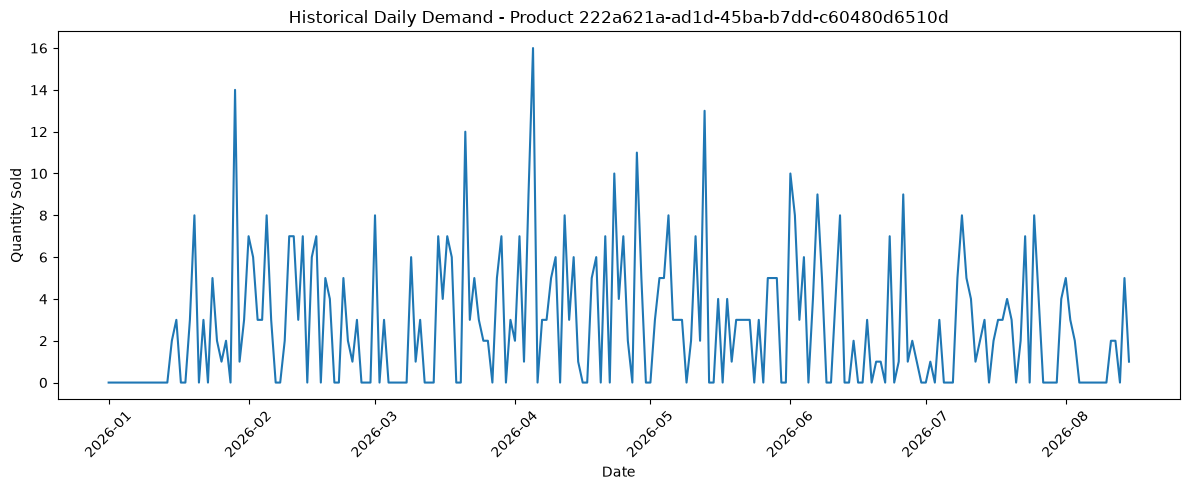

Selected product: 222a621a-ad1d-45ba-b7dd-c60480d6510d
Historical records: 227


In [5]:

top_product = (
    daily_sales.groupby("ProductID")["Demand"]
    .sum()
    .idxmax()
)

product_history = daily_sales[
    daily_sales["ProductID"] == top_product
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    product_history["Date"],
    product_history["Demand"]
)

plt.title(
    f"Historical Daily Demand - Product {top_product}"
)

plt.xlabel("Date")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Selected product:", top_product)
print("Historical records:", len(product_history))


In [6]:

daily_sales["ProductCode"] = (
    daily_sales["ProductID"]
    .astype("category")
    .cat.codes
)

daily_sales["DayOfWeek"] = (
    daily_sales["Date"].dt.dayofweek
)

daily_sales["DayOfMonth"] = (
    daily_sales["Date"].dt.day
)

daily_sales["Month"] = (
    daily_sales["Date"].dt.month
)

daily_sales["Lag_1"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(1)
)

daily_sales["Lag_7"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(7)
)

daily_sales["Lag_14"] = (
    daily_sales.groupby("ProductID")["Demand"].shift(14)
)

daily_sales["RollingMean_7"] = (
    daily_sales.groupby("ProductID")["Demand"]
    .transform(
        lambda s: s.shift(1).rolling(7).mean()
    )
)

daily_sales["RollingMean_14"] = (
    daily_sales.groupby("ProductID")["Demand"]
    .transform(
        lambda s: s.shift(1).rolling(14).mean()
    )
)

daily_sales = daily_sales.dropna().reset_index(drop=True)

feature_columns = [
    "ProductCode",
    "DayOfWeek",
    "DayOfMonth",
    "Month",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "RollingMean_7",
    "RollingMean_14"
]

print("Feature engineering completed")
print("Available features:", feature_columns)
print("Rows after feature engineering:", len(daily_sales))
print(daily_sales.head())


Feature engineering completed
Available features: ['ProductCode', 'DayOfWeek', 'DayOfMonth', 'Month', 'Lag_1', 'Lag_7', 'Lag_14', 'RollingMean_7', 'RollingMean_14']
Rows after feature engineering: 25773
                              ProductID       Date  Demand  ProductCode  \
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-15     2.0            0   
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16     6.0            0   
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-17     2.0            0   
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-18     0.0            0   
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-19     3.0            0   

   DayOfWeek  DayOfMonth  Month  Lag_1  Lag_7  Lag_14  RollingMean_7  \
0          3          15      1    0.0    0.0     0.0       0.000000   
1          4          16      1    2.0    0.0     0.0       0.285714   
2          5          17      1    6.0    0.0     0.0       1.142857   
3          6          18      1    2.0    0.0     0.0     

In [7]:

split_date = (
    daily_sales["Date"].max()
    - pd.Timedelta(days=13)
)

train_data = daily_sales[
    daily_sales["Date"] < split_date
].copy()

test_data = daily_sales[
    daily_sales["Date"] >= split_date
].copy()

X_train = train_data[feature_columns]
y_train = train_data["Demand"]

X_test = test_data[feature_columns]
y_test = test_data["Demand"]

print("TRAINING AND TESTING SPLIT")

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("Training ends:", train_data["Date"].max())
print("Testing starts:", test_data["Date"].min())
print("Testing ends:", test_data["Date"].max())

print("Unique training dates:", train_data["Date"].nunique())
print("Unique testing dates:", test_data["Date"].nunique())


TRAINING AND TESTING SPLIT
Training records: 24079
Testing records: 1694
Training ends: 2026-08-01 00:00:00
Testing starts: 2026-08-02 00:00:00
Testing ends: 2026-08-15 00:00:00
Unique training dates: 199
Unique testing dates: 14


In [8]:

lightgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=20,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

lightgbm_model.fit(
    X_train,
    y_train
)

print("Original LightGBM training completed")


Original LightGBM training completed


In [9]:

original_lightgbm_predictions = np.maximum(
    lightgbm_model.predict(X_test),
    0
)

original_lightgbm_mae = mean_absolute_error(
    y_test,
    original_lightgbm_predictions
)

original_lightgbm_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        original_lightgbm_predictions
    )
)

original_lightgbm_r2 = r2_score(
    y_test,
    original_lightgbm_predictions
)

print("ORIGINAL LIGHTGBM EVALUATION")

print("MAE:", round(original_lightgbm_mae, 3))
print("RMSE:", round(original_lightgbm_rmse, 3))
print("R2 Score:", round(original_lightgbm_r2, 3))


ORIGINAL LIGHTGBM EVALUATION
MAE: 1.155
RMSE: 1.653
R2 Score: 0.004


In [10]:

baseline_predictions = np.maximum(
    test_data["Lag_1"].to_numpy(),
    0
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

print("PREVIOUS-DAY BASELINE COMPARISON")

print("Baseline MAE:", round(baseline_mae, 3))
print(
    "Original LightGBM MAE:",
    round(original_lightgbm_mae, 3)
)

if original_lightgbm_mae < baseline_mae:
    print("LightGBM performs better than the baseline.")
else:
    print("Baseline performs better than LightGBM.")


PREVIOUS-DAY BASELINE COMPARISON
Baseline MAE: 1.407
Original LightGBM MAE: 1.155
LightGBM performs better than the baseline.


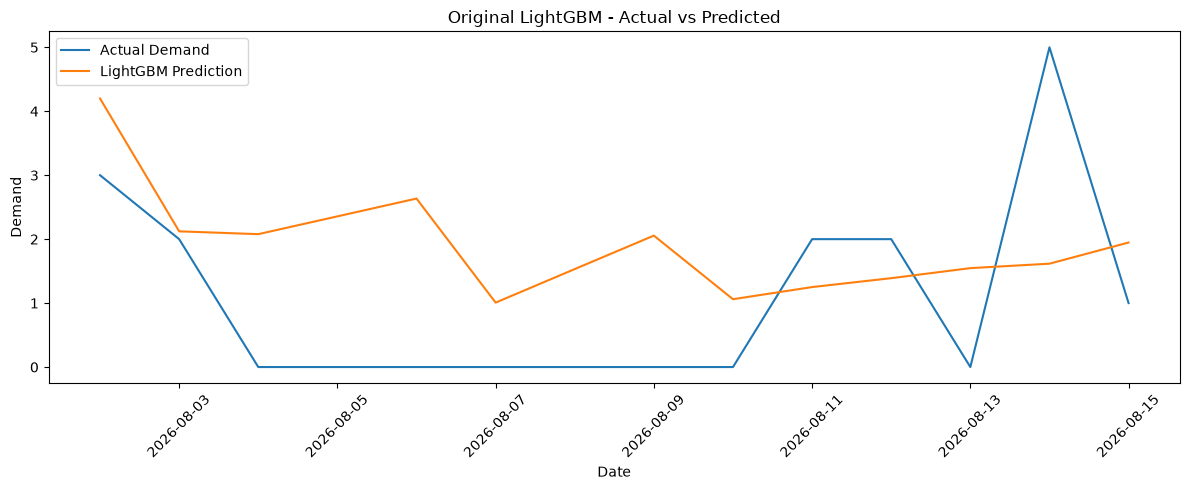

Selected product test records: 14


In [11]:

original_comparison = test_data[
    ["Date", "ProductID", "Demand"]
].copy()

original_comparison["PredictedDemand"] = (
    original_lightgbm_predictions
)

original_lightgbm_product = original_comparison[
    original_comparison["ProductID"] == top_product
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    original_lightgbm_product["Date"],
    original_lightgbm_product["Demand"],
    label="Actual Demand"
)

plt.plot(
    original_lightgbm_product["Date"],
    original_lightgbm_product["PredictedDemand"],
    label="LightGBM Prediction"
)

plt.title("Original LightGBM - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Selected product test records:",
      len(original_lightgbm_product))


In [12]:

prophet_data = product_history[
    ["Date", "Demand"]
].rename(
    columns={
        "Date": "ds",
        "Demand": "y"
    }
)

prophet_train = prophet_data[
    prophet_data["ds"] < split_date
].copy()

prophet_test = prophet_data[
    prophet_data["ds"] >= split_date
].copy()

print("PROPHET DATA PREPARATION")

print("Training records:", len(prophet_train))
print("Testing records:", len(prophet_test))

print("Training ends:", prophet_train["ds"].max())
print("Testing starts:", prophet_test["ds"].min())
print("Testing ends:", prophet_test["ds"].max())


PROPHET DATA PREPARATION
Training records: 213
Testing records: 14
Training ends: 2026-08-01 00:00:00
Testing starts: 2026-08-02 00:00:00
Testing ends: 2026-08-15 00:00:00


In [13]:

prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

print("Original Prophet training completed")


23:23:24 - cmdstanpy - INFO - Chain [1] start processing
23:23:25 - cmdstanpy - INFO - Chain [1] done processing


Original Prophet training completed


In [14]:

original_prophet_forecast = prophet_model.predict(
    prophet_test[["ds"]]
)

original_prophet_predictions = np.maximum(
    original_prophet_forecast["yhat"].to_numpy(),
    0
)

prophet_actual = prophet_test["y"].to_numpy()

original_prophet_mae = mean_absolute_error(
    prophet_actual,
    original_prophet_predictions
)

original_prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        original_prophet_predictions
    )
)

original_prophet_r2 = r2_score(
    prophet_actual,
    original_prophet_predictions
)

print("ORIGINAL PROPHET EVALUATION")

print("MAE:", round(original_prophet_mae, 3))
print("RMSE:", round(original_prophet_rmse, 3))
print("R2 Score:", round(original_prophet_r2, 3))


ORIGINAL PROPHET EVALUATION
MAE: 2.351
RMSE: 2.569
R2 Score: -1.988


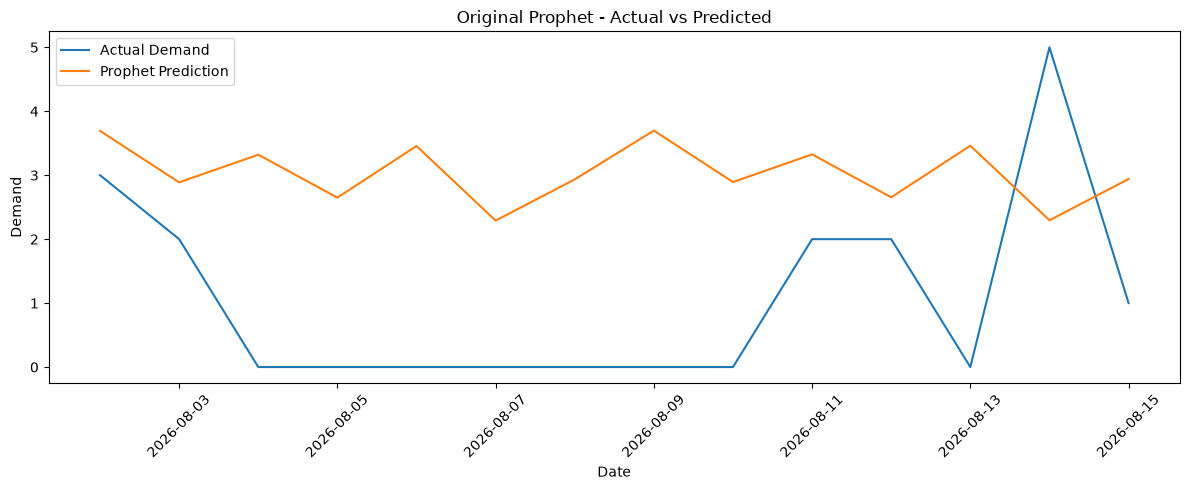

In [15]:

plt.figure(figsize=(12, 5))

plt.plot(
    prophet_test["ds"],
    prophet_actual,
    label="Actual Demand"
)

plt.plot(
    prophet_test["ds"],
    original_prophet_predictions,
    label="Prophet Prediction"
)

plt.title("Original Prophet - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [16]:

original_eval = prophet_test[
    ["ds", "y"]
].copy()

original_eval["ProphetPrediction"] = (
    original_prophet_predictions
)

original_eval = original_eval.merge(
    original_lightgbm_product[
        ["Date", "PredictedDemand"]
    ],
    left_on="ds",
    right_on="Date",
    how="inner"
).sort_values("ds").reset_index(drop=True)

if len(original_eval) != len(prophet_test):
    raise ValueError(
        "LightGBM and Prophet test dates do not match."
    )

original_actual = original_eval["y"].to_numpy()

original_lgbm_selected = (
    original_eval["PredictedDemand"].to_numpy()
)

original_prophet_selected = (
    original_eval["ProphetPrediction"].to_numpy()
)

print("Matching historical test records:", len(original_eval))
print("Original model comparison data prepared.")


Matching historical test records: 14
Original model comparison data prepared.


In [17]:

from itertools import product
from sklearn.model_selection import TimeSeriesSplit

unique_dates = np.array(
    sorted(train_data["Date"].unique())
)

if len(unique_dates) < 56:
    raise ValueError(
        "Not enough training dates for the selected time-series validation."
    )

tscv = TimeSeriesSplit(
    n_splits=3,
    test_size=14
)

parameter_combinations = list(product(
    [15, 31],
    [0.03, 0.05],
    [300, 500],
    [10, 20]
))

lightgbm_tuning_results = []

for leaves, rate, estimators, child_samples in parameter_combinations:

    fold_errors = []

    for train_idx, val_idx in tscv.split(unique_dates):

        fold_train_dates = unique_dates[train_idx]
        fold_val_dates = unique_dates[val_idx]

        fold_train = train_data[
            train_data["Date"].isin(fold_train_dates)
        ]

        fold_val = train_data[
            train_data["Date"].isin(fold_val_dates)
        ]

        model = LGBMRegressor(
            n_estimators=estimators,
            learning_rate=rate,
            num_leaves=leaves,
            min_child_samples=child_samples,
            max_depth=-1,
            random_state=42,
            verbosity=-1
        )

        model.fit(
            fold_train[feature_columns],
            fold_train["Demand"]
        )

        predictions = np.maximum(
            model.predict(
                fold_val[feature_columns]
            ),
            0
        )

        error = mean_absolute_error(
            fold_val["Demand"],
            predictions
        )

        fold_errors.append(error)

    lightgbm_tuning_results.append({
        "num_leaves": leaves,
        "learning_rate": rate,
        "n_estimators": estimators,
        "min_child_samples": child_samples,
        "CV_MAE": np.mean(fold_errors)
    })

lightgbm_tuning = pd.DataFrame(
    lightgbm_tuning_results
)

lightgbm_tuning = lightgbm_tuning.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("LIGHTGBM HYPERPARAMETER TUNING RESULTS")

print(
    lightgbm_tuning.round(4).to_string(index=False)
)

best_lightgbm_params = lightgbm_tuning.iloc[0]

print("\nBEST LIGHTGBM PARAMETERS")
print(best_lightgbm_params)


LIGHTGBM HYPERPARAMETER TUNING RESULTS
 num_leaves  learning_rate  n_estimators  min_child_samples  CV_MAE
         15           0.03           300                 20  1.3210
         15           0.03           300                 10  1.3242
         31           0.03           300                 20  1.3265
         15           0.05           300                 10  1.3276
         15           0.03           500                 20  1.3296
         15           0.05           300                 20  1.3317
         15           0.03           500                 10  1.3328
         31           0.03           300                 10  1.3339
         15           0.05           500                 10  1.3359
         31           0.05           300                 20  1.3361
         15           0.05           500                 20  1.3384
         31           0.03           500                 20  1.3445
         31           0.05           500                 20  1.3500
         

In [18]:

best_lightgbm_model = LGBMRegressor(
    n_estimators=int(
        best_lightgbm_params["n_estimators"]
    ),
    learning_rate=float(
        best_lightgbm_params["learning_rate"]
    ),
    num_leaves=int(
        best_lightgbm_params["num_leaves"]
    ),
    min_child_samples=int(
        best_lightgbm_params["min_child_samples"]
    ),
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

best_lightgbm_model.fit(
    X_train,
    y_train
)

print("Tuned LightGBM training completed")


Tuned LightGBM training completed


In [19]:

tuned_lightgbm_predictions = np.maximum(
    best_lightgbm_model.predict(X_test),
    0
)

tuned_lightgbm_mae = mean_absolute_error(
    y_test,
    tuned_lightgbm_predictions
)

tuned_lightgbm_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_lightgbm_predictions
    )
)

tuned_lightgbm_r2 = r2_score(
    y_test,
    tuned_lightgbm_predictions
)

print("TUNED LIGHTGBM EVALUATION")

print("MAE:", round(tuned_lightgbm_mae, 3))
print("RMSE:", round(tuned_lightgbm_rmse, 3))
print("R2 Score:", round(tuned_lightgbm_r2, 3))


TUNED LIGHTGBM EVALUATION
MAE: 1.159
RMSE: 1.648
R2 Score: 0.01


Tuned LightGBM product records: 14


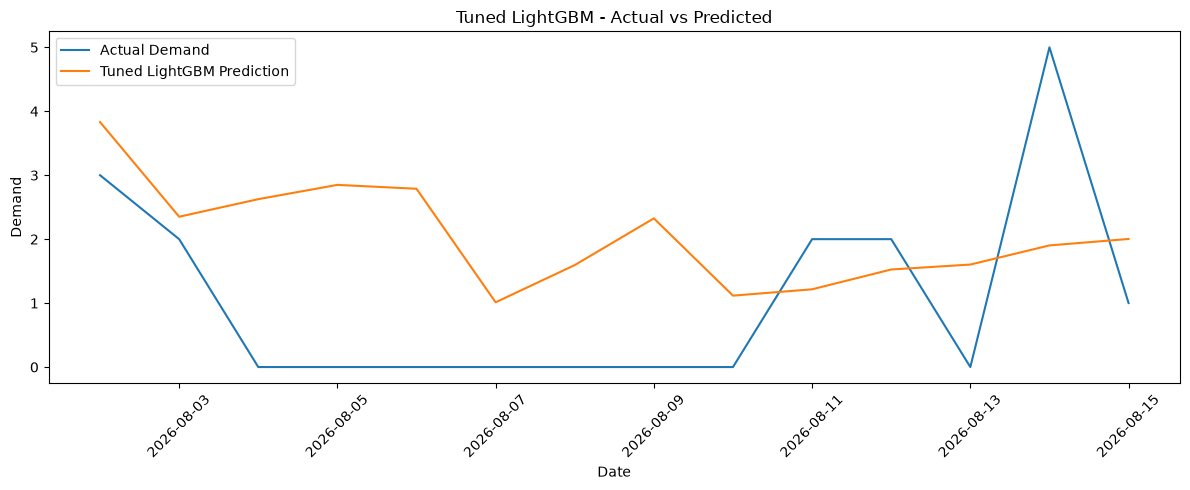

In [20]:

tuned_comparison = test_data[
    ["Date", "ProductID", "Demand"]
].copy()

tuned_comparison["PredictedDemand"] = (
    tuned_lightgbm_predictions
)

tuned_lightgbm_product = tuned_comparison[
    tuned_comparison["ProductID"] == top_product
].copy()

print("Tuned LightGBM product records:",
      len(tuned_lightgbm_product))

plt.figure(figsize=(12, 5))

plt.plot(
    tuned_lightgbm_product["Date"],
    tuned_lightgbm_product["Demand"],
    label="Actual Demand"
)

plt.plot(
    tuned_lightgbm_product["Date"],
    tuned_lightgbm_product["PredictedDemand"],
    label="Tuned LightGBM Prediction"
)

plt.title("Tuned LightGBM - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [21]:

from itertools import product

prophet_parameters = list(product(
    [0.01, 0.05, 0.1],
    [5.0, 10.0],
    ["additive", "multiplicative"]
))

prophet_dates = np.sort(
    prophet_train["ds"].unique()
)

fold_starts = [
    int(len(prophet_dates) * 0.60),
    int(len(prophet_dates) * 0.72),
    int(len(prophet_dates) * 0.84)
]

prophet_tuning_results = []

for change_scale, season_scale, mode in prophet_parameters:

    fold_errors = []

    for start in fold_starts:

        validation_dates = prophet_dates[
            start:start + 14
        ]

        if len(validation_dates) == 0:
            continue

        training_fold = prophet_train[
            prophet_train["ds"] < validation_dates[0]
        ].copy()

        validation_fold = prophet_train[
            prophet_train["ds"].isin(validation_dates)
        ].copy()

        if len(training_fold) < 30 or len(validation_fold) == 0:
            continue

        model = Prophet(
            yearly_seasonality=False,
            weekly_seasonality=True,
            daily_seasonality=False,
            changepoint_prior_scale=change_scale,
            seasonality_prior_scale=season_scale,
            seasonality_mode=mode
        )

        model.fit(training_fold)

        forecast = model.predict(
            validation_fold[["ds"]]
        )

        predictions = np.maximum(
            forecast["yhat"].to_numpy(),
            0
        )

        error = mean_absolute_error(
            validation_fold["y"].to_numpy(),
            predictions
        )

        fold_errors.append(error)

    if len(fold_errors) > 0:

        prophet_tuning_results.append({
            "changepoint_prior_scale": change_scale,
            "seasonality_prior_scale": season_scale,
            "seasonality_mode": mode,
            "CV_MAE": np.mean(fold_errors)
        })

prophet_tuning = pd.DataFrame(
    prophet_tuning_results
)

if prophet_tuning.empty:
    raise ValueError(
        "Prophet tuning did not produce results. Check training history."
    )

prophet_tuning = prophet_tuning.sort_values(
    "CV_MAE"
).reset_index(drop=True)

print("PROPHET HYPERPARAMETER TUNING RESULTS")

print(
    prophet_tuning.round(4).to_string(index=False)
)

best_prophet_params = prophet_tuning.iloc[0]

print("\nBEST PROPHET PARAMETERS")
print(best_prophet_params)


23:24:27 - cmdstanpy - INFO - Chain [1] start processing
23:24:27 - cmdstanpy - INFO - Chain [1] done processing
23:24:28 - cmdstanpy - INFO - Chain [1] start processing
23:24:28 - cmdstanpy - INFO - Chain [1] done processing
23:24:28 - cmdstanpy - INFO - Chain [1] start processing
23:24:28 - cmdstanpy - INFO - Chain [1] done processing
23:24:28 - cmdstanpy - INFO - Chain [1] start processing
23:24:28 - cmdstanpy - INFO - Chain [1] done processing
23:24:29 - cmdstanpy - INFO - Chain [1] start processing
23:24:29 - cmdstanpy - INFO - Chain [1] done processing
23:24:29 - cmdstanpy - INFO - Chain [1] start processing
23:24:29 - cmdstanpy - INFO - Chain [1] done processing
23:24:30 - cmdstanpy - INFO - Chain [1] start processing
23:24:30 - cmdstanpy - INFO - Chain [1] done processing
23:24:30 - cmdstanpy - INFO - Chain [1] start processing
23:24:30 - cmdstanpy - INFO - Chain [1] done processing
23:24:30 - cmdstanpy - INFO - Chain [1] start processing
23:24:31 - cmdstanpy - INFO - Chain [1]

PROPHET HYPERPARAMETER TUNING RESULTS
 changepoint_prior_scale  seasonality_prior_scale seasonality_mode  CV_MAE
                    0.10                     10.0         additive  3.0836
                    0.10                      5.0         additive  3.0845
                    0.05                      5.0         additive  3.1537
                    0.05                     10.0         additive  3.1541
                    0.10                      5.0   multiplicative  3.2404
                    0.10                     10.0   multiplicative  3.2487
                    0.05                     10.0   multiplicative  3.2542
                    0.01                     10.0         additive  3.2906
                    0.05                      5.0   multiplicative  3.3013
                    0.01                     10.0   multiplicative  3.3966
                    0.01                      5.0   multiplicative  3.4687
                    0.01                      5.0         addi

In [22]:

best_prophet_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=float(
        best_prophet_params["changepoint_prior_scale"]
    ),
    seasonality_prior_scale=float(
        best_prophet_params["seasonality_prior_scale"]
    ),
    seasonality_mode=best_prophet_params["seasonality_mode"]
)

best_prophet_model.fit(
    prophet_train
)

print("Tuned Prophet training completed")


23:24:45 - cmdstanpy - INFO - Chain [1] start processing
23:24:45 - cmdstanpy - INFO - Chain [1] done processing


Tuned Prophet training completed


In [23]:

tuned_prophet_forecast = best_prophet_model.predict(
    prophet_test[["ds"]]
)

tuned_prophet_predictions = np.maximum(
    tuned_prophet_forecast["yhat"].to_numpy(),
    0
)

tuned_prophet_mae = mean_absolute_error(
    prophet_test["y"],
    tuned_prophet_predictions
)

tuned_prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_test["y"],
        tuned_prophet_predictions
    )
)

tuned_prophet_r2 = r2_score(
    prophet_test["y"],
    tuned_prophet_predictions
)

print("TUNED PROPHET EVALUATION")

print("MAE:", round(tuned_prophet_mae, 3))
print("RMSE:", round(tuned_prophet_rmse, 3))
print("R2 Score:", round(tuned_prophet_r2, 3))


TUNED PROPHET EVALUATION
MAE: 1.889
RMSE: 2.187
R2 Score: -1.165


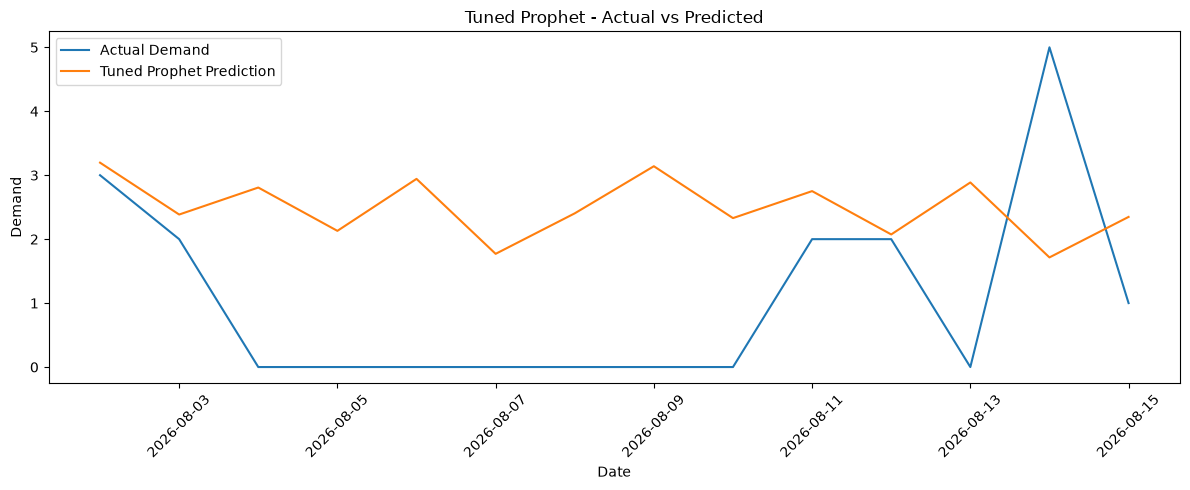

In [24]:

plt.figure(figsize=(12, 5))

plt.plot(
    prophet_test["ds"],
    prophet_test["y"],
    label="Actual Demand"
)

plt.plot(
    prophet_test["ds"],
    tuned_prophet_predictions,
    label="Tuned Prophet Prediction"
)

plt.title("Tuned Prophet - Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [25]:

def recursive_lightgbm_forecast(
    model,
    product_id,
    historical_data,
    forecast_dates
):

    product_data = historical_data[
        historical_data["ProductID"] == product_id
    ].sort_values("Date")

    history = product_data[
        product_data["Date"] < split_date
    ]["Demand"].astype(float).tolist()

    product_code = int(
        product_data["ProductCode"].iloc[0]
    )

    predictions = []

    for forecast_date in forecast_dates:

        if len(history) < 14:
            raise ValueError(
                "Not enough historical demand for lag features."
            )

        features = pd.DataFrame([{
            "ProductCode": product_code,
            "DayOfWeek": forecast_date.dayofweek,
            "DayOfMonth": forecast_date.day,
            "Month": forecast_date.month,
            "Lag_1": history[-1],
            "Lag_7": history[-7],
            "Lag_14": history[-14],
            "RollingMean_7": np.mean(history[-7:]),
            "RollingMean_14": np.mean(history[-14:])
        }])

        features = features[feature_columns]

        prediction = max(
            0,
            float(model.predict(features)[0])
        )

        predictions.append(prediction)

        # Use the prediction for the next forecast day
        history.append(prediction)

    return np.array(predictions)


forecast_dates = prophet_test["ds"].tolist()

# Original LightGBM recursive predictions
original_recursive_predictions = recursive_lightgbm_forecast(
    lightgbm_model,
    top_product,
    daily_sales,
    forecast_dates
)

# Tuned LightGBM recursive predictions
tuned_recursive_predictions = recursive_lightgbm_forecast(
    best_lightgbm_model,
    top_product,
    daily_sales,
    forecast_dates
)

print("Recursive forecasting completed")

print("Original predictions:", len(original_recursive_predictions))
print("Tuned predictions:", len(tuned_recursive_predictions))
print("Prophet predictions:", len(tuned_prophet_predictions))


Recursive forecasting completed
Original predictions: 14
Tuned predictions: 14
Prophet predictions: 14


In [26]:

# Prepare Prophet test results
prophet_eval = prophet_test[
    ["ds", "y"]
].copy()

prophet_eval["ProphetPrediction"] = (
    tuned_prophet_predictions
)

# Prepare tuned LightGBM results for selected product
lightgbm_eval = tuned_lightgbm_product[
    ["Date", "Demand", "PredictedDemand"]
].copy()

# Match both models using the same dates
final_eval = prophet_eval.merge(
    lightgbm_eval,
    left_on="ds",
    right_on="Date",
    how="inner"
).sort_values("ds").reset_index(drop=True)

if len(final_eval) != len(prophet_test):
    raise ValueError(
        "The test dates do not match. Check both model predictions."
    )

# Actual demand
actual = final_eval["y"].to_numpy()

# Tuned model predictions
lightgbm_pred = np.maximum(
    final_eval["PredictedDemand"].to_numpy(),
    0
)

prophet_pred = np.maximum(
    final_eval["ProphetPrediction"].to_numpy(),
    0
)

print("FINAL EVALUATION DATA")

print("Actual records:", len(actual))
print("LightGBM records:", len(lightgbm_pred))
print("Prophet records:", len(prophet_pred))

print(final_eval[
    ["ds", "y", "PredictedDemand", "ProphetPrediction"]
])


FINAL EVALUATION DATA
Actual records: 14
LightGBM records: 14
Prophet records: 14
           ds    y  PredictedDemand  ProphetPrediction
0  2026-08-02  3.0         3.831354           3.196238
1  2026-08-03  2.0         2.350729           2.385033
2  2026-08-04  0.0         2.625333           2.807169
3  2026-08-05  0.0         2.848940           2.129698
4  2026-08-06  0.0         2.788110           2.942607
5  2026-08-07  0.0         1.012407           1.770286
6  2026-08-08  0.0         1.594550           2.403717
7  2026-08-09  0.0         2.325206           3.140337
8  2026-08-10  0.0         1.116533           2.329133
9  2026-08-11  2.0         1.215711           2.751269
10 2026-08-12  2.0         1.525434           2.073798
11 2026-08-13  0.0         1.602852           2.886706
12 2026-08-14  5.0         1.901974           1.714386
13 2026-08-15  1.0         2.002914           2.347817


In [27]:

def calculate_all_metrics(actual, predicted):

    # Regression metrics
    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(
        actual,
        predicted
    )

    # Classification-based demand occurrence metrics
    # Actual > 0 means demand occurred
    # Predicted >= 0.5 means demand is predicted

    actual_classes = (
        np.asarray(actual) > 0
    ).astype(int)

    predicted_classes = (
        np.asarray(predicted) >= 0.5
    ).astype(int)

    accuracy = accuracy_score(
        actual_classes,
        predicted_classes
    )

    precision = precision_score(
        actual_classes,
        predicted_classes,
        zero_division=0
    )

    recall = recall_score(
        actual_classes,
        predicted_classes,
        zero_division=0
    )

    f1 = f1_score(
        actual_classes,
        predicted_classes,
        zero_division=0
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


lightgbm_final_metrics = calculate_all_metrics(
    actual,
    lightgbm_pred
)

prophet_final_metrics = calculate_all_metrics(
    actual,
    prophet_pred
)

print("Both models evaluated successfully.")


Both models evaluated successfully.


In [28]:

model_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        **lightgbm_final_metrics
    },
    {
        "Model": "Prophet",
        **prophet_final_metrics
    }
])

print("\nFINAL MODEL COMPARISON")
print("=" * 100)

print(
    model_comparison.round(3).to_string(index=False)
)

print("\nBest model according to MAE:")

best_model = model_comparison.sort_values(
    ["MAE", "RMSE"],
    ascending=[True, True]
).iloc[0]

print(best_model["Model"])



FINAL MODEL COMPARISON
   Model   MAE  RMSE     R2  Accuracy  Precision  Recall  F1 Score
LightGBM 1.604 1.848 -0.546     0.429      0.429     1.0       0.6
 Prophet 1.889 2.187 -1.165     0.429      0.429     1.0       0.6

Best model according to MAE:
LightGBM


In [29]:

actual_classes = (actual > 0).astype(int)

lightgbm_classes = (
    lightgbm_pred >= 0.5
).astype(int)

prophet_classes = (
    prophet_pred >= 0.5
).astype(int)

print("LIGHTGBM CONFUSION MATRIX")

print(
    confusion_matrix(
        actual_classes,
        lightgbm_classes
    )
)

print("\nPROPHET CONFUSION MATRIX")

print(
    confusion_matrix(
        actual_classes,
        prophet_classes
    )
)


LIGHTGBM CONFUSION MATRIX
[[0 8]
 [0 6]]

PROPHET CONFUSION MATRIX
[[0 8]
 [0 6]]


In [30]:

# Original model predictions on the same selected product
original_lightgbm_metrics = calculate_all_metrics(
    original_actual,
    original_lgbm_selected
)

original_prophet_metrics = calculate_all_metrics(
    original_actual,
    original_prophet_selected
)

# Tuned model predictions on the same selected product
tuned_lightgbm_metrics = calculate_all_metrics(
    actual,
    lightgbm_pred
)

tuned_prophet_metrics = calculate_all_metrics(
    actual,
    prophet_pred
)

tuning_comparison = pd.DataFrame([
    {
        "Model": "LightGBM",
        "Original MAE": original_lightgbm_metrics["MAE"],
        "Tuned MAE": tuned_lightgbm_metrics["MAE"],
        "MAE Improvement": (
            original_lightgbm_metrics["MAE"]
            - tuned_lightgbm_metrics["MAE"]
        ),
        "Original RMSE": original_lightgbm_metrics["RMSE"],
        "Tuned RMSE": tuned_lightgbm_metrics["RMSE"]
    },
    {
        "Model": "Prophet",
        "Original MAE": original_prophet_metrics["MAE"],
        "Tuned MAE": tuned_prophet_metrics["MAE"],
        "MAE Improvement": (
            original_prophet_metrics["MAE"]
            - tuned_prophet_metrics["MAE"]
        ),
        "Original RMSE": original_prophet_metrics["RMSE"],
        "Tuned RMSE": tuned_prophet_metrics["RMSE"]
    }
])

print("ORIGINAL VS TUNED MODEL PERFORMANCE")

print(
    tuning_comparison.round(3).to_string(index=False)
)


ORIGINAL VS TUNED MODEL PERFORMANCE
   Model  Original MAE  Tuned MAE  MAE Improvement  Original RMSE  Tuned RMSE
LightGBM         1.520      1.604           -0.084          1.745       1.848
 Prophet         2.351      1.889            0.462          2.569       2.187


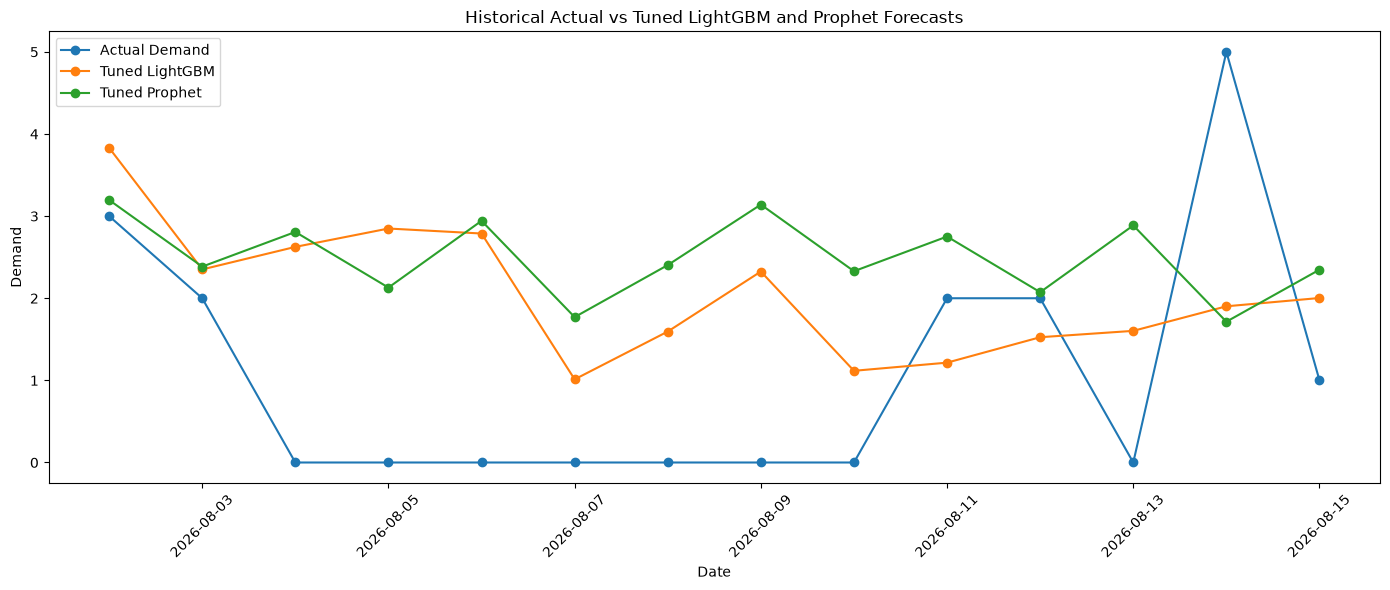

In [31]:

plt.figure(figsize=(14, 6))

plt.plot(
    final_eval["ds"],
    actual,
    marker="o",
    label="Actual Demand"
)

plt.plot(
    final_eval["ds"],
    lightgbm_pred,
    marker="o",
    label="Tuned LightGBM"
)

plt.plot(
    final_eval["ds"],
    prophet_pred,
    marker="o",
    label="Tuned Prophet"
)

plt.title(
    "Historical Actual vs Tuned LightGBM and Prophet Forecasts"
)

plt.xlabel("Date")
plt.ylabel("Demand")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [32]:

lightgbm_mae = lightgbm_final_metrics["MAE"]
prophet_mae = prophet_final_metrics["MAE"]

lightgbm_rmse = lightgbm_final_metrics["RMSE"]
prophet_rmse = prophet_final_metrics["RMSE"]

print("FINAL DEMAND FORECASTING RECOMMENDATION")
print("=" * 50)

if lightgbm_mae < prophet_mae:

    selected_model = "LightGBM"

    print("Recommended Model: LightGBM")

elif prophet_mae < lightgbm_mae:

    selected_model = "Prophet"

    print("Recommended Model: Prophet")

else:

    if lightgbm_rmse < prophet_rmse:
        selected_model = "LightGBM"
    elif prophet_rmse < lightgbm_rmse:
        selected_model = "Prophet"
    else:
        selected_model = "No clear winner"

    print("Recommended Model:", selected_model)

print("\nLightGBM MAE:", round(lightgbm_mae, 3))
print("Prophet MAE:", round(prophet_mae, 3))

print("LightGBM RMSE:", round(lightgbm_rmse, 3))
print("Prophet RMSE:", round(prophet_rmse, 3))

print("\nSelected model:", selected_model)


FINAL DEMAND FORECASTING RECOMMENDATION
Recommended Model: LightGBM

LightGBM MAE: 1.604
Prophet MAE: 1.889
LightGBM RMSE: 1.848
Prophet RMSE: 2.187

Selected model: LightGBM


In [33]:

# Original LightGBM results
original_lightgbm_product = pd.DataFrame({
    "Date": forecast_dates,
    "PredictedDemand": original_recursive_predictions
})

# Tuned LightGBM results
tuned_lightgbm_product = pd.DataFrame({
    "Date": forecast_dates,
    "PredictedDemand": tuned_recursive_predictions
})

# Original model evaluation
original_eval = prophet_test[
    ["ds", "y"]
].copy()

original_eval["LightGBMPrediction"] = (
    original_recursive_predictions
)

original_eval["ProphetPrediction"] = (
    original_prophet_predictions
)

original_actual = original_eval["y"].to_numpy()

original_lgbm_selected = (
    original_eval["LightGBMPrediction"].to_numpy()
)

original_prophet_selected = (
    original_eval["ProphetPrediction"].to_numpy()
)

# Tuned model evaluation
final_eval = prophet_test[
    ["ds", "y"]
].copy()

final_eval["PredictedDemand"] = (
    tuned_recursive_predictions
)

final_eval["ProphetPrediction"] = (
    tuned_prophet_predictions
)

actual = final_eval["y"].to_numpy()

lightgbm_pred = final_eval[
    "PredictedDemand"
].to_numpy()

prophet_pred = final_eval[
    "ProphetPrediction"
].to_numpy()

print("FINAL FAIR COMPARISON DATA")

print("Actual:", len(actual))
print("LightGBM:", len(lightgbm_pred))
print("Prophet:", len(prophet_pred))

print(final_eval.round(3))


FINAL FAIR COMPARISON DATA
Actual: 14
LightGBM: 14
Prophet: 14
             ds    y  PredictedDemand  ProphetPrediction
3164 2026-08-02  3.0            3.831              3.196
3165 2026-08-03  2.0            2.951              2.385
3166 2026-08-04  0.0            3.418              2.807
3167 2026-08-05  0.0            3.604              2.130
3168 2026-08-06  0.0            4.204              2.943
3169 2026-08-07  0.0            1.999              1.770
3170 2026-08-08  0.0            3.594              2.404
3171 2026-08-09  0.0            2.785              3.140
3172 2026-08-10  0.0            2.204              2.329
3173 2026-08-11  2.0            2.855              2.751
3174 2026-08-12  2.0            2.237              2.074
3175 2026-08-13  0.0            3.110              2.887
3176 2026-08-14  5.0            2.719              1.714
3177 2026-08-15  1.0            2.792              2.348


In [34]:

from pathlib import Path
import joblib
import pickle
import pandas as pd
from prophet import Prophet
from prophet.serialize import model_to_json

project_root = Path(
    "C:/Users/RSCH/Desktop/DWD/Final project/"
    "Retail-Intelligence-Platform"
)

model_dir = (
    project_root / "backend" / "ml" /
    "forecasting" / "models"
)

model_dir.mkdir(parents=True, exist_ok=True)

prophet_model_dir = model_dir / "prophet_models"
prophet_model_dir.mkdir(parents=True, exist_ok=True)

print("Model folder:", model_dir)
print("Prophet folder:", prophet_model_dir)


Model folder: C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\forecasting\models
Prophet folder: C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\forecasting\models\prophet_models


In [38]:

# FINAL ORIGINAL LIGHTGBM MODEL

import joblib

final_lightgbm = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=20,
    max_depth=-1,
    random_state=42,
    verbosity=-1
)

# Train using the complete historical dataset
final_lightgbm.fit(
    daily_sales[feature_columns],
    daily_sales["Demand"]
)

# Product ID mapping
product_code_map = (
    daily_sales[["ProductID", "ProductCode"]]
    .drop_duplicates()
)

# Save using the existing filename and structure
joblib.dump(
    {
        "model": final_lightgbm,
        "feature_columns": feature_columns,
        "product_code_map": dict(
            zip(
                product_code_map["ProductID"].astype(str),
                product_code_map["ProductCode"]
            )
        )
    },
    model_dir / "lightgbm_model.pkl"
)

print("Original LightGBM model saved successfully.")



Original LightGBM model saved successfully.


In [36]:

joblib.dump(
    daily_sales[["ProductID", "Date", "Demand"]].copy(),
    model_dir / "daily_history.pkl"
)

print("Daily demand history saved successfully.")


Daily demand history saved successfully.


In [39]:


# FINAL TUNED PROPHET MODELS

import pickle
from prophet import Prophet
from prophet.serialize import model_to_json

prophet_model_dir = model_dir / "prophet_models"
prophet_model_dir.mkdir(parents=True, exist_ok=True)

model_index = {}
training_summary = []

for product_id, product_data in daily_sales.groupby("ProductID"):

    product_data = (
        product_data[["Date", "Demand"]]
        .sort_values("Date")
    )

    prophet_data = product_data.rename(
        columns={
            "Date": "ds",
            "Demand": "y"
        }
    )

    nonzero_days = int(
        (prophet_data["y"] > 0).sum()
    )

    if len(prophet_data) < 30 or nonzero_days < 3:
        training_summary.append({
            "ProductID": product_id,
            "Status": "Insufficient history"
        })
        continue

    # Use tuned Prophet parameters
    model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=float(
            best_prophet_params["changepoint_prior_scale"]
        ),
        seasonality_prior_scale=float(
            best_prophet_params["seasonality_prior_scale"]
        ),
        seasonality_mode=best_prophet_params["seasonality_mode"]
    )

    model.fit(prophet_data)

    model_filename = (
        f"product_{len(model_index):04d}.json"
    )

    with open(
        prophet_model_dir / model_filename,
        "w",
        encoding="utf-8"
    ) as file:
        file.write(model_to_json(model))

    model_index[str(product_id)] = model_filename

    training_summary.append({
        "ProductID": product_id,
        "Status": "Tuned Prophet model saved"
    })

# Save product-to-model mapping
with open(
    prophet_model_dir / "model_index.pkl",
    "wb"
) as file:
    pickle.dump(model_index, file)

summary = pd.DataFrame(training_summary)

summary.to_csv(
    prophet_model_dir / "training_summary.csv",
    index=False
)

print("Tuned Prophet models saved:", len(model_index))
print("Prophet model saving completed.")


00:49:58 - cmdstanpy - INFO - Chain [1] start processing
00:49:58 - cmdstanpy - INFO - Chain [1] done processing
00:49:58 - cmdstanpy - INFO - Chain [1] start processing
00:49:59 - cmdstanpy - INFO - Chain [1] done processing
00:49:59 - cmdstanpy - INFO - Chain [1] start processing
00:49:59 - cmdstanpy - INFO - Chain [1] done processing
00:50:00 - cmdstanpy - INFO - Chain [1] start processing
00:50:00 - cmdstanpy - INFO - Chain [1] done processing
00:50:01 - cmdstanpy - INFO - Chain [1] start processing
00:50:01 - cmdstanpy - INFO - Chain [1] done processing
00:50:01 - cmdstanpy - INFO - Chain [1] start processing
00:50:01 - cmdstanpy - INFO - Chain [1] done processing
00:50:02 - cmdstanpy - INFO - Chain [1] start processing
00:50:02 - cmdstanpy - INFO - Chain [1] done processing
00:50:03 - cmdstanpy - INFO - Chain [1] start processing
00:50:03 - cmdstanpy - INFO - Chain [1] done processing
00:50:03 - cmdstanpy - INFO - Chain [1] start processing
00:50:03 - cmdstanpy - INFO - Chain [1]

Tuned Prophet models saved: 121
Prophet model saving completed.
